## IMPORT DATA AND PROCESSING

In [3]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

import seaborn as sns
import matplotlib.pyplot as plt

# lib data preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# lib supervised learning
from sklearn.tree import DecisionTreeClassifier

# library evaluation model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## LOAD DATASET

In [4]:
dataset = sns.load_dataset("penguins")
print(dataset.tail(3))

    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex
341  Gentoo  Biscoe            50.4           15.7              222.0       5750.0    Male
342  Gentoo  Biscoe            45.2           14.8              212.0       5200.0  Female
343  Gentoo  Biscoe            49.9           16.1              213.0       5400.0    Male


## SHOW DATASET

In [5]:
# show metadata
print(np.round(dataset.describe(),2))

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          342.00         342.00             342.00       342.00
mean            43.92          17.15             200.92      4201.75
std              5.46           1.97              14.06       801.95
min             32.10          13.10             172.00      2700.00
25%             39.22          15.60             190.00      3550.00
50%             44.45          17.30             197.00      4050.00
75%             48.50          18.70             213.00      4750.00
max             59.60          21.50             231.00      6300.00


In [6]:
# show dataset
print(dataset)

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex
0    Adelie  Torgersen            39.1           18.7              181.0       3750.0    Male
1    Adelie  Torgersen            39.5           17.4              186.0       3800.0  Female
2    Adelie  Torgersen            40.3           18.0              195.0       3250.0  Female
3    Adelie  Torgersen             NaN            NaN                NaN          NaN     NaN
4    Adelie  Torgersen            36.7           19.3              193.0       3450.0  Female
..      ...        ...             ...            ...                ...          ...     ...
339  Gentoo     Biscoe             NaN            NaN                NaN          NaN     NaN
340  Gentoo     Biscoe            46.8           14.3              215.0       4850.0  Female
341  Gentoo     Biscoe            50.4           15.7              222.0       5750.0    Male
342  Gentoo     Biscoe            45.2           14.8       

## GRAPHIC BARPLOT DATASET

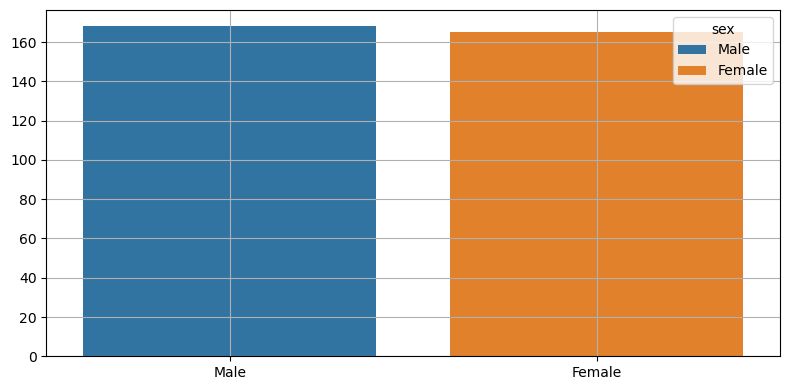

In [7]:
# create barplot
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(dataset, x="sex", hue="sex")
 
# set labels
ax.set_title("", fontsize=14)
ax.set_xlabel("", fontsize=12)
ax.set_ylabel("", fontsize=12)
ax.grid(True)
 
# show plot
plt.tight_layout()
plt.show()

## GRAPHICS WITH ORDERED DATASET

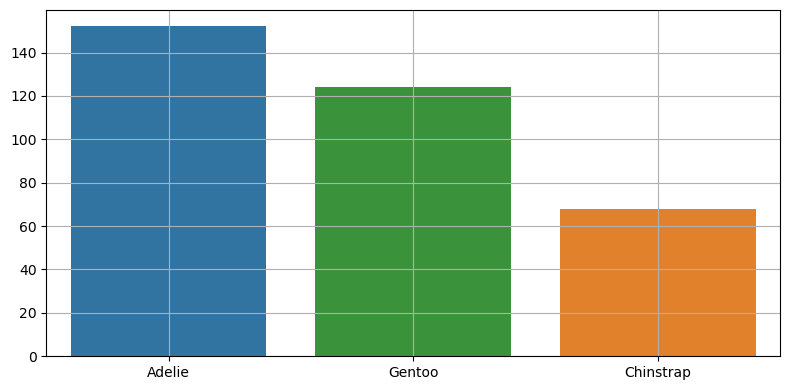

In [8]:
#hitung jumlah penguins
order_species = dataset['species'].value_counts().index

# create barplot
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(data=dataset, x="species", hue="species", order=order_species, ax=ax)

# set labels
ax.set_title("", fontsize=14)
ax.set_xlabel("", fontsize=12)
ax.set_ylabel("", fontsize=12)
ax.grid(True)
 
# show plot
plt.tight_layout()
plt.show()

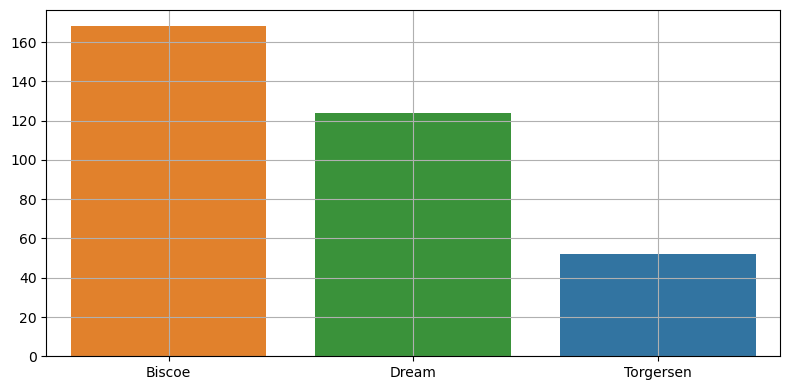

In [9]:
#hitung jumlah penguins
order_island = dataset['island'].value_counts().index

# create barplot
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(data=dataset, x="island", hue="island", order=order_island, ax=ax)

# set labels
ax.set_title("", fontsize=14)
ax.set_xlabel("", fontsize=12)
ax.set_ylabel("", fontsize=12)
ax.grid(True)
 
# show plot
plt.tight_layout()
plt.show()

## CLEARED DATASET

In [10]:
dataset = dataset.dropna(subset=['sex'])

## SET FITURE AND LABEL

In [11]:
# Set features and Labels
x = dataset[["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]].values 
y = dataset["sex"].values

# normalize features
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(x)

## SPLIT DATA SET TESTING AND TRAINING

In [12]:
# split validation
trainX, testX, trainY, testY = train_test_split(
  scaled, y, test_size=0.3, random_state=7, shuffle=True
)

# show dimension of data train
print(trainX.shape, trainY.shape)

(233, 4) (233,)


In [13]:
# show dimension of data test
print(testX.shape, testY.shape)

(100, 4) (100,)


## RESULT SUPERVISED LEARNING

In [14]:
result_C45 = DecisionTreeClassifier(criterion="gini", random_state=None).fit(trainX, trainY).predict(testX)
print(result_C45)

['Female' 'Male' 'Male' 'Male' 'Male' 'Female' 'Female' 'Male' 'Female'
 'Female' 'Female' 'Male' 'Male' 'Female' 'Male' 'Female' 'Male' 'Female'
 'Male' 'Male' 'Male' 'Female' 'Female' 'Female' 'Female' 'Male' 'Female'
 'Male' 'Female' 'Female' 'Female' 'Female' 'Female' 'Female' 'Female'
 'Female' 'Female' 'Male' 'Female' 'Male' 'Female' 'Female' 'Female'
 'Female' 'Male' 'Female' 'Female' 'Female' 'Female' 'Female' 'Male'
 'Female' 'Female' 'Male' 'Female' 'Female' 'Female' 'Female' 'Male'
 'Male' 'Male' 'Male' 'Male' 'Female' 'Male' 'Female' 'Female' 'Female'
 'Female' 'Female' 'Male' 'Female' 'Female' 'Male' 'Male' 'Female'
 'Female' 'Female' 'Male' 'Female' 'Male' 'Female' 'Male' 'Female' 'Male'
 'Male' 'Male' 'Male' 'Male' 'Male' 'Male' 'Male' 'Female' 'Female'
 'Female' 'Male' 'Male' 'Female' 'Female' 'Female']


## SET CONFUSION MATRIX

In [15]:
conf_C45 = confusion_matrix(testY, result_C45)
print(conf_C45)

[[51  4]
 [ 8 37]]


Text(45.722222222222214, 0.5, 'True Label')

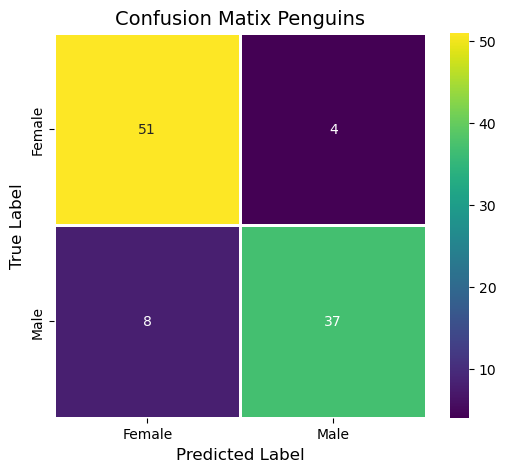

In [19]:
#Barplot - Countplot
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(conf_C45, annot=True, cmap="viridis", fmt="d", linewidths=1,
            xticklabels=["Female", "Male"], yticklabels=["Female", "Male"])

#Set Label
ax.set_title("Confusion Matix Penguins", fontsize=14)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)

## REPORT EVALUATION CLASSIFICATION

In [17]:
# evaluation models - classification_report
print(classification_report(y_true=testY, y_pred=result_C45))

              precision    recall  f1-score   support

      Female       0.86      0.93      0.89        55
        Male       0.90      0.82      0.86        45

    accuracy                           0.88       100
   macro avg       0.88      0.87      0.88       100
weighted avg       0.88      0.88      0.88       100

